In [1]:
import cv2
import polars as pl
import numpy as np
import matplotlib.pyplot as plt

In [1]:
import numpy as np

# Define coefficients [a, b, c]
coeffs = [0.0692, -0.865, -0.398]

# Solve
roots = np.roots(coeffs)

print(f"Roots found: {roots}")

Roots found: [12.94432185 -0.44432185]


In [2]:
def processar_video(caminho_video):
    # 1. Carregar o Vídeo
    cap = cv2.VideoCapture(caminho_video)
    
    if not cap.isOpened():
        print("Erro: Não foi possível abrir o vídeo.")
        return

    # Obter FPS (Frames por Segundo) para calcular o tempo corretamente
    fps = cap.get(cv2.CAP_PROP_FPS)
    print(f"Vídeo carregado. FPS detectado: {fps}")

    # 2. Configurar o Rastreador (Tracker)
    # Usamos o CSRT que é robusto, mas um pouco mais lento. Ótimo para precisão.
    tracker = cv2.TrackerCSRT_create()

    # Ler o primeiro frame
    ret, frame = cap.read()
    if not ret:
        print("Erro ao ler o primeiro frame.")
        return

    print("PASSO 1: Desenhe um retângulo à volta da bolinha preta e pressione ENTER ou ESPAÇO.")
    # Abre uma janela para você selecionar a bolinha manualmente
    roi = cv2.selectROI("Selecione o Marcador", frame, fromCenter=False, showCrosshair=True)
    tracker.init(frame, roi)
    cv2.destroyWindow("Selecione o Marcador")

    # Listas para guardar os dados brutos
    dados_y = []
    frames = []
    frame_count = 0

    print("A processar vídeo... (Pressione 'q' para interromper)")

    # 3. Loop de Processamento (Frame a Frame)
    while True:
        ret, frame = cap.read()
        if not ret:
            break

        # Atualizar o rastreador
        sucesso, box = tracker.update(frame)

        if sucesso:
            # A box retorna (x, y, largura, altura)
            x, y, w, h = [int(v) for v in box]
            
            # Calculamos o centro da bolinha
            centro_y = y + h // 2
            centro_x = x + w // 2

            # Guardamos apenas a posição Y (que é a vibração principal da régua)
            dados_y.append(centro_y)
            frames.append(frame_count)

            # Desenhar na tela para você ver a acontecer
            cv2.rectangle(frame, (x, y), (x + w, y + h), (0, 255, 0), 2)
            cv2.circle(frame, (centro_x, centro_y), 3, (0, 0, 255), -1)
        
        cv2.imshow("Rastreamento em Tempo Real", frame)
        
        # Pressione 'q' para sair mais cedo
        if cv2.waitKey(1) & 0xFF == ord('q'):
            break
        
        frame_count += 1

    cap.release()
    cv2.destroyAllWindows()

    # 4. Análise de Dados com POLARS
    print("A gerar gráficos com Polars...")
    
    # Criar DataFrame
    df = pl.DataFrame({
        "frame": frames,
        "pixel_y": dados_y
    })

    # Criar coluna de Tempo (segundos)
    df = df.with_columns(
        (pl.col("frame") / fps).alias("tempo_s")
    )

    # Remover a média (DC offset) para a vibração oscilar em torno de zero
    media_y = df["pixel_y"].mean()
    df = df.with_columns(
        (pl.col("pixel_y") - media_y).alias("amplitude")
    )

    # 5. Calcular a FFT (Transformada de Fourier) usando NumPy
    sinal = df["amplitude"].to_numpy()
    n = len(sinal)
    
    # FFT
    fft_vals = np.fft.fft(sinal)
    fft_freqs = np.fft.fftfreq(n, d=1/fps)

    # Pegar apenas a metade positiva do espectro
    metade_n = n // 2
    frequencias = fft_freqs[:metade_n]
    amplitudes = np.abs(fft_vals)[:metade_n]

    # 6. Plotar Resultados
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

    # Gráfico 1: Domínio do Tempo (O que a câmera viu)
    ax1.plot(df["tempo_s"], df["amplitude"], color='blue')
    ax1.set_title("Vibração no Domínio do Tempo")
    ax1.set_xlabel("Tempo (s)")
    ax1.set_ylabel("Deslocamento (pixels)")
    ax1.grid(True)

    # Gráfico 2: Domínio da Frequência (O que a física diz)
    ax2.plot(frequencias, amplitudes, color='red')
    ax2.set_title("Espectro de Frequência (FFT)")
    ax2.set_xlabel("Frequência (Hz)")
    ax2.set_ylabel("Magnitude")
    ax2.set_xlim(0, 30) # Limitamos a 30Hz pois é o foco da sua Nikon/Régua
    ax2.grid(True)
    
    # Encontrar o pico máximo
    pico_idx = np.argmax(amplitudes)
    freq_pico = frequencias[pico_idx]
    ax2.annotate(f'Pico: {freq_pico:.2f} Hz', 
                 xy=(freq_pico, amplitudes[pico_idx]), 
                 xytext=(freq_pico+2, amplitudes[pico_idx]),
                 arrowprops=dict(facecolor='black', shrink=0.05))

    plt.tight_layout()
    plt.show()

In [ ]:
# --- COMO USAR ---
# Substitua pelo nome do seu vídeo gravado
# Se o vídeo estiver na mesma pasta, basta o nome.
arquivo_video = "teste_regua.mp4" 

# Tente processar (certifique-se que o arquivo existe)
try:
    processar_video(arquivo_video)
except Exception as e:
    print(f"Ocorreu um erro. Verifique se o nome do vídeo está correto.\nErro: {e}")

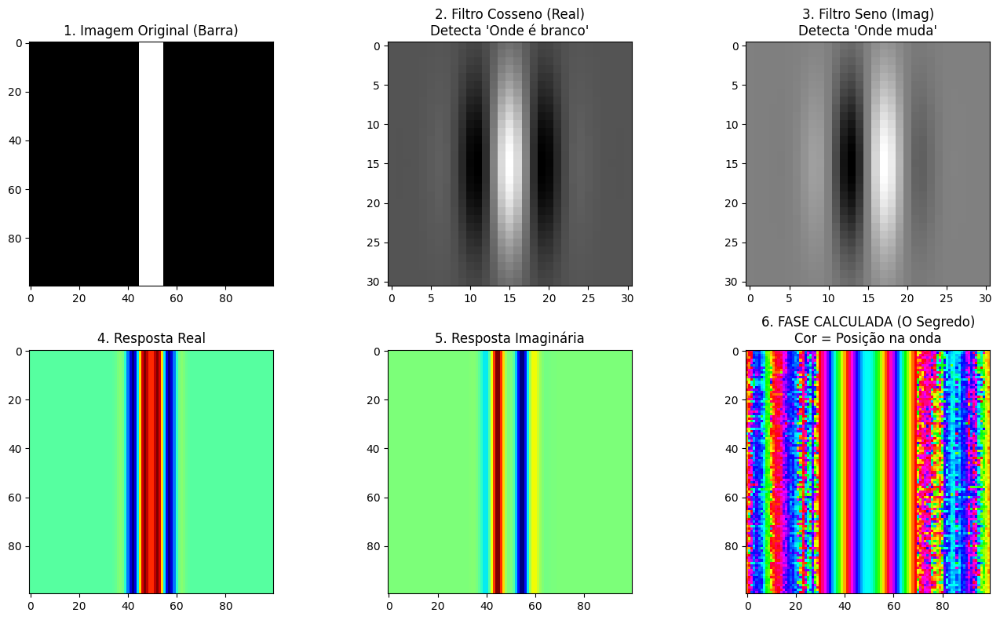

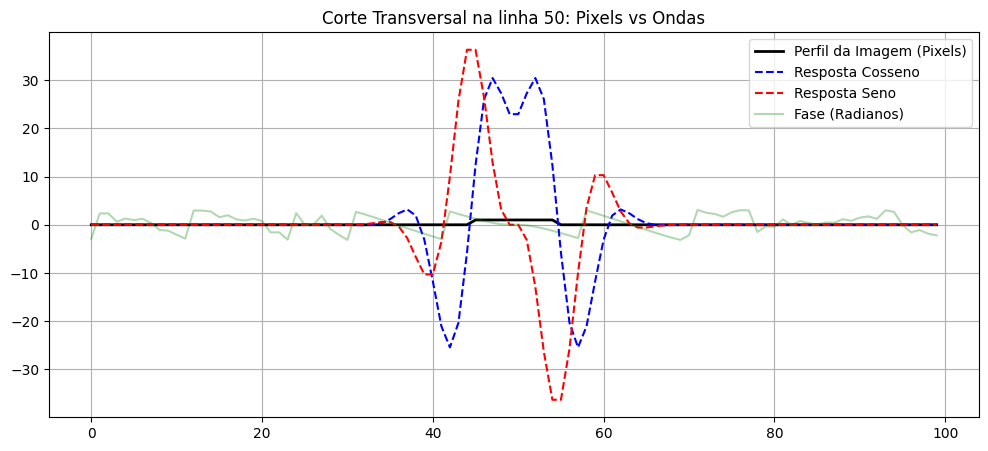

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def visualizar_ondas_gabor():
    # 1. CRIAR UMA IMAGEM SINTÉTICA (Simples)
    # 100x100 pixels, fundo preto (0)
    img = np.zeros((100, 100), dtype=np.float32)
    # Desenhamos uma barra branca (valor 1.0) no meio. Essa é a nossa "borda"
    img[:, 45:55] = 1.0

    # 2. CRIAR OS FILTROS DE GABOR (Os "Moldes" de Onda)
    # Parâmetros do filtro
    ksize = 31       # Tamanho do filtro (31x31 pixels)
    sigma = 4.0      # Desvio padrão da Gaussiana (largura do envelope)
    theta = 0        # Orientação: 0 = Vertical (para pegar nossa barra vertical)
    lambd = 10.0     # Comprimento da onda (wavelength) em pixels
    gamma = 0.5      # Aspect ratio espacial
    
    # Filtro REAL (Cosseno) - Fase offset (psi) = 0
    # Este filtro procura por intensidade (brilho)
    kernel_real = cv2.getGaborKernel((ksize, ksize), sigma, theta, lambd, gamma, 0, ktype=cv2.CV_32F)
    
    # Filtro IMAGINÁRIO (Seno) - Fase offset (psi) = pi/2
    # Este filtro procura por transições (bordas)
    kernel_imag = cv2.getGaborKernel((ksize, ksize), sigma, theta, lambd, gamma, np.pi/2, ktype=cv2.CV_32F)

    # 3. APLICAR A CONVOLUÇÃO (Passar o filtro na imagem)
    res_real = cv2.filter2D(img, cv2.CV_32F, kernel_real)
    res_imag = cv2.filter2D(img, cv2.CV_32F, kernel_imag)

    # 4. CALCULAR AMPLITUDE E FASE LOCAL
    # Aqui está a mágica da pirâmide complexa simplificada
    amplitude = np.sqrt(res_real**2 + res_imag**2)
    fase = np.arctan2(res_imag, res_real)

    # --- VISUALIZAÇÃO ---
    plt.figure(figsize=(14, 8))

    # A: Imagem Original e Filtros
    plt.subplot(2, 3, 1)
    plt.imshow(img, cmap='gray')
    plt.title("1. Imagem Original (Barra)")
    
    plt.subplot(2, 3, 2)
    plt.imshow(kernel_real, cmap='gray')
    plt.title("2. Filtro Cosseno (Real)\nDetecta 'Onde é branco'")

    plt.subplot(2, 3, 3)
    plt.imshow(kernel_imag, cmap='gray')
    plt.title("3. Filtro Seno (Imag)\nDetecta 'Onde muda'")

    # B: Respostas dos Filtros
    plt.subplot(2, 3, 4)
    plt.imshow(res_real, cmap='jet')
    plt.title("4. Resposta Real")

    plt.subplot(2, 3, 5)
    plt.imshow(res_imag, cmap='jet')
    plt.title("5. Resposta Imaginária")
    
    plt.subplot(2, 3, 6)
    plt.imshow(fase, cmap='hsv') # HSV é bom para fase cíclica (-pi a pi)
    plt.title("6. FASE CALCULADA (O Segredo)\nCor = Posição na onda")

    plt.tight_layout()
    plt.show()

    # --- GRÁFICO 1D (O CORTA-MATO) ---
    # Vamos pegar uma linha horizontal (pixel 50) e ver os valores como gráfico
    linha = 50
    plt.figure(figsize=(12, 5))
    
    plt.plot(img[linha, :], 'k-', linewidth=2, label='Perfil da Imagem (Pixels)')
    plt.plot(res_real[linha, :], 'b--', label='Resposta Cosseno')
    plt.plot(res_imag[linha, :], 'r--', label='Resposta Seno')
    plt.plot(fase[linha, :], 'g-', alpha=0.3, label='Fase (Radianos)')
    
    plt.title(f"Corte Transversal na linha {linha}: Pixels vs Ondas")
    plt.legend()
    plt.grid(True)
    plt.show()

if __name__ == "__main__":
    visualizar_ondas_gabor()

Tentando carregar: Images/logo volvo.png
Linha de análise Horizontal: 64
Analisando Coluna Vertical: 28


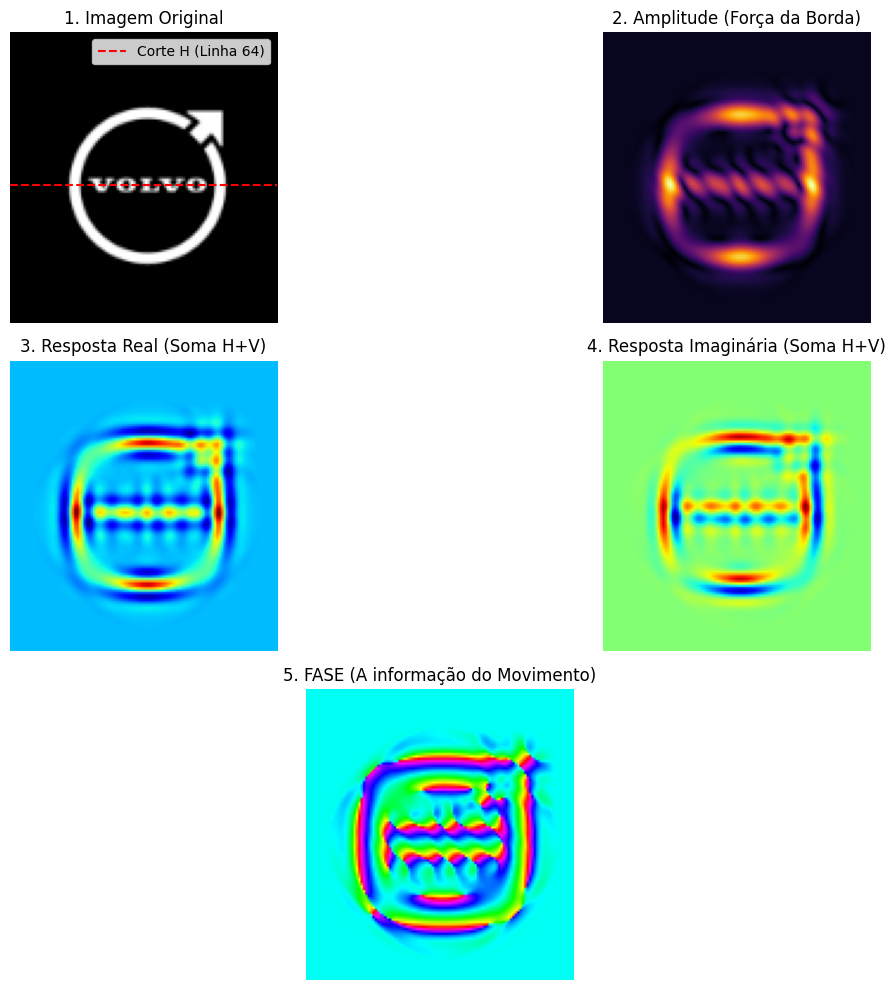

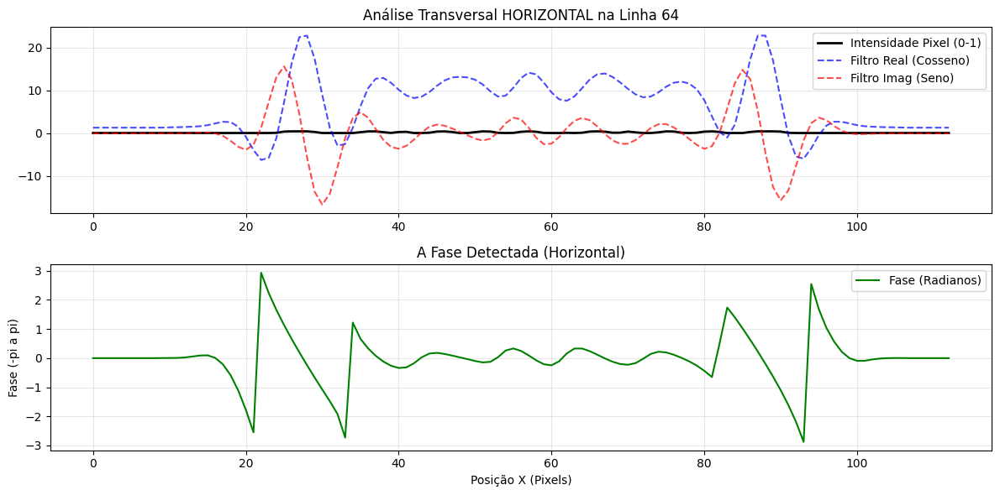

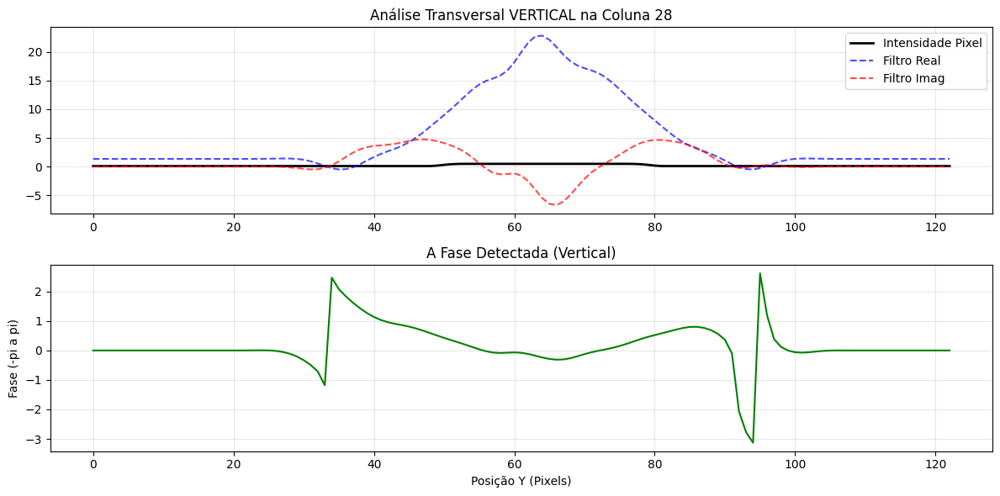

In [20]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import sys

# --- CONFIGURAÇÃO ---
# Certifique-se que o arquivo existe na pasta Images
NOME_DA_IMAGEM = "Images/logo volvo.png" 
# --------------------

def visualizar_ondas_gabor_completo(caminho_imagem):
    # 1. CARREGAR E PREPARAR A IMAGEM REAL
    print(f"Tentando carregar: {caminho_imagem}")
    img_raw = cv2.imread(caminho_imagem, cv2.IMREAD_GRAYSCALE)

    if img_raw is None:
        print(f"\nERRO CRÍTICO: Não foi possível abrir a imagem '{caminho_imagem}'.")
        print("Verifique se o caminho está correto.")
        sys.exit()

    # Converter para float32 (0.0 a 1.0)
    img = img_raw.astype(np.float32) / 255.0

    # Redimensionar se necessário (para não travar o PC com imagens 4K)
    altura, largura = img.shape[:2]
    if largura > 800:
        fator = 800 / largura
        img = cv2.resize(img, (int(largura*fator), int(altura*fator)))
        print(f"Imagem redimensionada para: {img.shape}")
    
    # 2. CRIAR OS FILTROS DE GABOR
    ksize = 31
    sigma = 4.0
    lambd = 10.0
    gamma = 0.5
    
    # --- DIREÇÃO 1: VERTICAL (Theta = 0) ---
    kern_real_v = cv2.getGaborKernel((ksize, ksize), sigma, 0, lambd, gamma, 0, ktype=cv2.CV_32F)
    kern_imag_v = cv2.getGaborKernel((ksize, ksize), sigma, 0, lambd, gamma, np.pi/2, ktype=cv2.CV_32F)
    
    # --- DIREÇÃO 2: HORIZONTAL (Theta = Pi/2) ---
    kern_real_h = cv2.getGaborKernel((ksize, ksize), sigma, np.pi/2, lambd, gamma, 0, ktype=cv2.CV_32F)
    kern_imag_h = cv2.getGaborKernel((ksize, ksize), sigma, np.pi/2, lambd, gamma, np.pi/2, ktype=cv2.CV_32F)

    # Aplicar filtros (Convolução)
    f_real_v = cv2.filter2D(img, cv2.CV_32F, kern_real_v)
    f_imag_v = cv2.filter2D(img, cv2.CV_32F, kern_imag_v)
    f_real_h = cv2.filter2D(img, cv2.CV_32F, kern_real_h)
    f_imag_h = cv2.filter2D(img, cv2.CV_32F, kern_imag_h)

    # SOMAR AS ENERGIAS (Combinar vertical e horizontal)
    # Isso garante que detectamos bordas em qualquer direção
    res_real = f_real_v + f_real_h
    res_imag = f_imag_v + f_imag_h

    # Calcular Amplitude e Fase combinadas
    amplitude = np.sqrt(res_real**2 + res_imag**2)
    fase = np.arctan2(res_imag, res_real)

    # Encontrar o ponto de maior energia para decidir onde cortar
    y_max, x_max = np.unravel_index(np.argmax(amplitude), amplitude.shape)
    linha_corte = y_max # Fixa para 50 ou use y_max para dinâmico
    print(f"Linha de análise Horizontal: {linha_corte}")

    # ==========================================
    # JANELA 1: O GRID DE IMAGENS (VISUALIZAÇÃO)
    # ==========================================
    plt.figure(figsize=(12, 10))

    # 1. Imagem Original com a linha de corte desenhada
    plt.subplot(3, 2, 1)
    img_com_linha = img.copy()
    plt.imshow(img, cmap='gray')
    # Desenha a linha vermelha no plot
    plt.axhline(y=linha_corte, color='r', linestyle='--', label=f'Corte H (Linha {linha_corte})') 
    plt.title(f"1. Imagem Original")
    plt.legend()
    plt.axis('off')

    plt.subplot(3, 2, 2)
    plt.imshow(amplitude, cmap='inferno')
    plt.title("2. Amplitude (Força da Borda)")
    plt.axis('off')

    plt.subplot(3, 2, 3)
    plt.imshow(res_real, cmap='jet')
    plt.title(f"3. Resposta Real (Soma H+V)")
    plt.axis('off')

    plt.subplot(3, 2, 4)
    plt.imshow(res_imag, cmap='jet')
    plt.title(f"4. Resposta Imaginária (Soma H+V)")
    plt.axis('off')
    
    plt.subplot(3, 1, 3)
    plt.imshow(fase, cmap='hsv') 
    plt.title("5. FASE (A informação do Movimento)")
    plt.axis('off')

    plt.tight_layout()

    # ==========================================
    # JANELA 2: GRÁFICO 1D - CORTE HORIZONTAL
    # (Analisa uma LINHA da esquerda para a direita)
    # ==========================================
    plt.figure(figsize=(12, 6))
    
    # Extrair dados daquela linha específica
    dados_pixel = img[linha_corte, :]
    dados_real = res_real[linha_corte, :]
    dados_imag = res_imag[linha_corte, :]
    dados_fase = fase[linha_corte, :]

    # Plotar Pixels vs Filtros
    plt.subplot(2, 1, 1)
    plt.plot(dados_pixel, 'k-', linewidth=2, label='Intensidade Pixel (0-1)')
    plt.plot(dados_real, 'b--', alpha=0.7, label='Filtro Real (Cosseno)')
    plt.plot(dados_imag, 'r--', alpha=0.7, label='Filtro Imag (Seno)')
    plt.title(f"Análise Transversal HORIZONTAL na Linha {linha_corte}")
    plt.legend(loc='upper right')
    plt.grid(True, alpha=0.3)

    # Plotar a Fase
    plt.subplot(2, 1, 2)
    plt.plot(dados_fase, 'g-', linewidth=1.5, label='Fase (Radianos)')
    plt.title("A Fase Detectada (Horizontal)")
    plt.ylabel("Fase (-pi a pi)")
    plt.xlabel("Posição X (Pixels)")
    plt.legend(loc='upper right')
    plt.grid(True, alpha=0.3)

    plt.tight_layout()

    # ==========================================
    # JANELA 3: GRÁFICO 1D - CORTE VERTICAL
    # (Analisa uma COLUNA de cima para baixo)
    # ==========================================
    
    # Usamos o X máximo encontrado anteriormente
    coluna_corte = x_max # Fixa para 50 ou use x_max para dinâmico 
    print(f"Analisando Coluna Vertical: {coluna_corte}")
    
    plt.figure(figsize=(12, 6))

    # NOTA: O slice agora é [:, coluna_corte] (Todas as linhas, uma coluna)
    dados_pixel_v = img[:, coluna_corte]
    dados_real_v = res_real[:, coluna_corte]
    dados_imag_v = res_imag[:, coluna_corte]
    dados_fase_v = fase[:, coluna_corte]

    # Plotar Pixels vs Filtros
    plt.subplot(2, 1, 1)
    # Eixo X agora representa a altura (Y) da imagem
    plt.plot(dados_pixel_v, 'k-', linewidth=2, label='Intensidade Pixel')
    plt.plot(dados_real_v, 'b--', alpha=0.7, label='Filtro Real')
    plt.plot(dados_imag_v, 'r--', alpha=0.7, label='Filtro Imag')
    plt.title(f"Análise Transversal VERTICAL na Coluna {coluna_corte}")
    plt.legend(loc='upper right')
    plt.grid(True, alpha=0.3)

    # Plotar a Fase
    plt.subplot(2, 1, 2)
    plt.plot(dados_fase_v, 'g-', linewidth=1.5, label='Fase (Radianos)')
    plt.title("A Fase Detectada (Vertical)")
    plt.ylabel("Fase (-pi a pi)")
    plt.xlabel("Posição Y (Pixels)")
    plt.grid(True, alpha=0.3)

    plt.tight_layout()
    
    plt.show()

if __name__ == "__main__":
    visualizar_ondas_gabor_completo(NOME_DA_IMAGEM)

Tentando carregar: Images/logo volvo.png
Dominante: VERTICAL (Corte na linha 64)


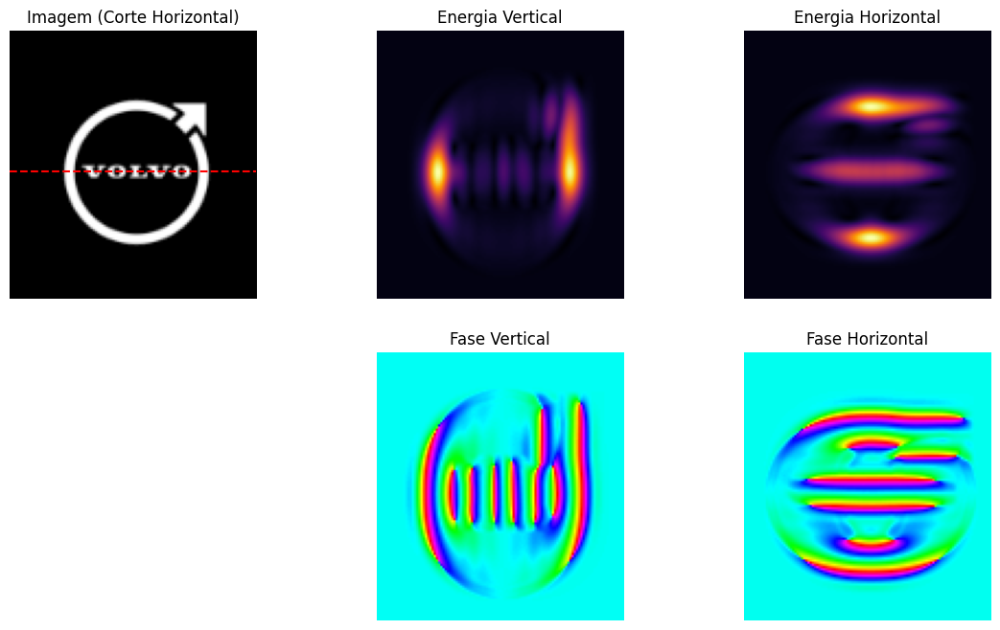

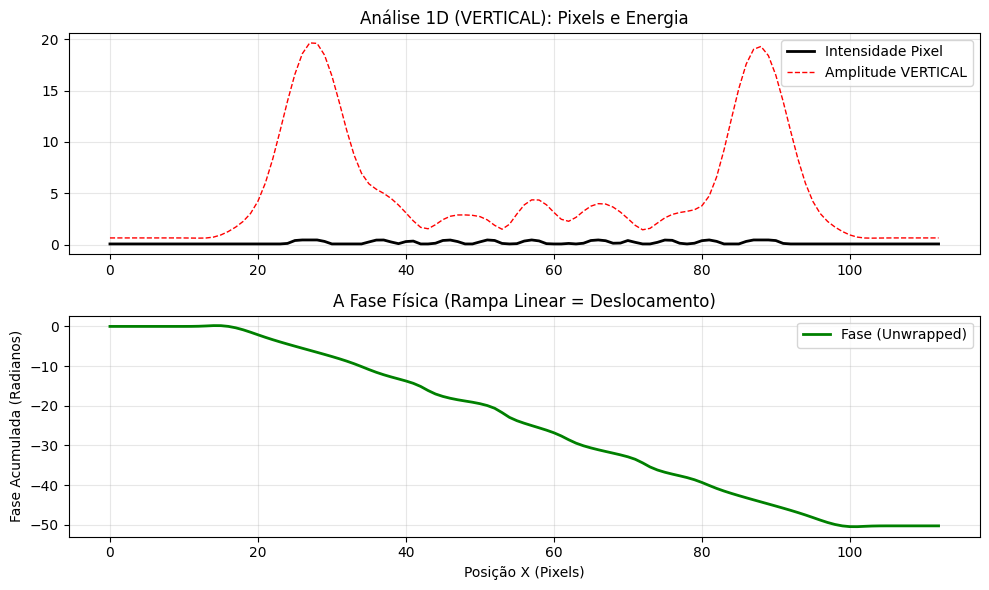

In [30]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import sys

# --- CONFIGURAÇÃO ---
NOME_DA_IMAGEM = "Images/logo volvo.png" 
# --------------------

def visualizar_ondas_gabor_correto(caminho_imagem):
    # 1. CARREGAR IMAGEM
    print(f"Tentando carregar: {caminho_imagem}")
    img_raw = cv2.imread(caminho_imagem, cv2.IMREAD_GRAYSCALE)

    if img_raw is None:
        print(f"ERRO: Não achei a imagem '{caminho_imagem}'.")
        sys.exit()

    img = img_raw.astype(np.float32) / 255.0
    
    # Redimensionar para processamento rápido (opcional)
    altura, largura = img.shape[:2]
    if largura > 800:
        fator = 800 / largura
        img = cv2.resize(img, (int(largura*fator), int(altura*fator)))

    # 2. DEFINIR FILTROS (GABOR)
    ksize = 31
    sigma = 4.0
    lambd = 10.0
    gamma = 0.5
    
    # --- FILTRO VERTICAL (Theta = 0) ---
    # Detecta bordas Verticais (que variam na horizontal)
    kern_real_v = cv2.getGaborKernel((ksize, ksize), sigma, 0, lambd, gamma, 0, ktype=cv2.CV_32F)
    kern_imag_v = cv2.getGaborKernel((ksize, ksize), sigma, 0, lambd, gamma, np.pi/2, ktype=cv2.CV_32F)
    
    # --- FILTRO HORIZONTAL (Theta = Pi/2) ---
    # Detecta bordas Horizontais (que variam na vertical)
    kern_real_h = cv2.getGaborKernel((ksize, ksize), sigma, np.pi/2, lambd, gamma, 0, ktype=cv2.CV_32F)
    kern_imag_h = cv2.getGaborKernel((ksize, ksize), sigma, np.pi/2, lambd, gamma, np.pi/2, ktype=cv2.CV_32F)

    # 3. APLICAR CONVOLUÇÃO (SEPARADO!)
    # Respostas para Vertical
    f_real_v = cv2.filter2D(img, cv2.CV_32F, kern_real_v)
    f_imag_v = cv2.filter2D(img, cv2.CV_32F, kern_imag_v)
    
    # Respostas para Horizontal
    f_real_h = cv2.filter2D(img, cv2.CV_32F, kern_real_h)
    f_imag_h = cv2.filter2D(img, cv2.CV_32F, kern_imag_h)

    # 4. CALCULAR AMPLITUDE E FASE (SEPARADO!)
    # Amplitude e Fase Vertical
    amp_v = np.sqrt(f_real_v**2 + f_imag_v**2)
    fase_v = np.arctan2(f_imag_v, f_real_v)

    # Amplitude e Fase Horizontal
    amp_h = np.sqrt(f_real_h**2 + f_imag_h**2)
    fase_h = np.arctan2(f_imag_h, f_real_h)

    # Para visualização geral, podemos somar AMPlitudes (energia), mas NUNCA as fases
    amp_total = amp_v + amp_h

    # 5. LÓGICA DE CORTE INTELIGENTE
    # Vamos achar o ponto mais forte da imagem
    y_max, x_max = np.unravel_index(np.argmax(amp_total), amp_total.shape)
    
    # Decidir qual direção domina nesse ponto
    forca_v = amp_v[y_max, x_max]
    forca_h = amp_h[y_max, x_max]

    if forca_v > forca_h:
        print(f"Dominante: VERTICAL (Corte na linha {y_max})")
        modo = "VERTICAL"
        # Se é vertical, cortamos uma linha horizontal para ver a variação
        dados_pixel = img[y_max, :]
        dados_fase = fase_v[y_max, :] # Usamos a fase V
        dados_amp = amp_v[y_max, :]
        eixo_label = "Posição X (Pixels)"
        corte_idx = y_max
        tipo_corte = "Horizontal" # O corte atravessa a borda vertical
    else:
        print(f"Dominante: HORIZONTAL (Corte na coluna {x_max})")
        modo = "HORIZONTAL"
        # Se é horizontal, cortamos uma coluna vertical para ver a variação
        dados_pixel = img[:, x_max]
        dados_fase = fase_h[:, x_max] # Usamos a fase H
        dados_amp = amp_h[:, x_max]
        eixo_label = "Posição Y (Pixels)"
        corte_idx = x_max
        tipo_corte = "Vertical"

    # Sugestão da análise: Unwrap na fase para o gráfico ficar bonito
    dados_fase_unwrap = np.unwrap(dados_fase)

    # ================= GRAFICSO ==================



    plt.figure(figsize=(14, 8))

    plt.subplot(2, 3, 1)
    plt.imshow(img, cmap='gray')
    if modo == "VERTICAL":
        plt.axhline(y=corte_idx, color='r', linestyle='--')
    else:
        plt.axvline(x=corte_idx, color='r', linestyle='--')
    plt.title(f"Imagem (Corte {tipo_corte})")
    plt.axis('off')

    plt.subplot(2, 3, 2)
    plt.imshow(amp_v, cmap='inferno')
    plt.title("Energia Vertical")
    plt.axis('off')

    # ================= GRAFICO 1==================
    plt.subplot(2, 3, 3)
    plt.imshow(amp_h, cmap='inferno')
    plt.title("Energia Horizontal")
    plt.axis('off')

    plt.subplot(2, 3, 5)
    plt.imshow(fase_v, cmap='hsv')
    plt.title("Fase Vertical")
    plt.axis('off')

    plt.subplot(2, 3, 6)
    plt.imshow(fase_h, cmap='hsv')
    plt.title("Fase Horizontal")
    plt.axis('off')

    plt.figure(figsize=(10, 6))
    
    plt.subplot(2, 1, 1)
    plt.plot(dados_pixel, 'k-', lw=2, label='Intensidade Pixel')
    plt.plot(dados_amp, 'r--', lw=1, label=f'Amplitude {modo}')
    plt.title(f"Análise 1D ({modo}): Pixels e Energia")
    plt.legend()
    plt.grid(True, alpha=0.3)

    plt.subplot(2, 1, 2)
    plt.plot(dados_fase_unwrap, 'g-', lw=2, label='Fase (Unwrapped)')
    plt.title("A Fase Física (Rampa Linear = Deslocamento)")
    plt.ylabel("Fase Acumulada (Radianos)")
    plt.xlabel(eixo_label)
    plt.grid(True, alpha=0.3)
    plt.legend()

    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    visualizar_ondas_gabor_correto(NOME_DA_IMAGEM)

In [1]:
import cv2 as cv
img = cv.imread("Images/logo volvo.png")
cv.imshow("Image", img)
cv.waitKey(0)


-1

In [ ]:
import cv2 as cv

capture = cv.VideoCapture('videos/video.mp4')

while True:
    isTrue, frame = capture.read()

    # Adicione esta verificação de segurança
    if not isTrue:
        print("Fim do vídeo ou arquivo não encontrado.")
        break

    cv.imshow('Video', frame)

    if cv.waitKey(20) & 0xFF==ord('d'):
        break

capture.release()
cv.destroyAllWindows()

Fim do vídeo ou arquivo não encontrado.


In [3]:
"""
Geração de gráficos para o TCC:
"Vibrometria óptica aplicada para medição de vibrações em testes dinâmicos de bancada"
Autor: Vinicius Andrade Trento

Gera 6 figuras:
  fig_regimes_amortecimento.png  -> 4 regimes da Tabela 1 (Seção 2.1.1)
  fig_subamortecido.png          -> apenas subamortecido (caso queira separado)
  fig_ressonancia.png            -> FRF com pico de ressonância (Seção 2.1.2)
  fig_perda_rigidez.png          -> shift de frequência por dano (Seção 2.1.4)
"""

import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------------------------
# Configuração visual consistente (estilo sóbrio, adequado a TCC)
# ---------------------------------------------------------------------------
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "legend.fontsize": 10,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})


# ===========================================================================
# 1) Quatro regimes de amortecimento (Tabela 1, Seção 2.1.1)
# ===========================================================================
def resposta_livre(t, zeta, wn, x0=1.0, v0=0.0):
    """
    Solução analítica da resposta livre de um sistema massa-mola-amortecedor
    de 1 GDL para condições iniciais x(0)=x0 e xdot(0)=v0.
    Cobre os quatro regimes em função de zeta.
    """
    if np.isclose(zeta, 0.0):
        # Não amortecido: oscilação harmônica permanente
        A = x0
        B = v0 / wn
        return A * np.cos(wn * t) + B * np.sin(wn * t)

    if zeta < 1.0:
        # Subamortecido
        wd = wn * np.sqrt(1 - zeta**2)
        A = x0
        B = (v0 + zeta * wn * x0) / wd
        return np.exp(-zeta * wn * t) * (A * np.cos(wd * t) + B * np.sin(wd * t))

    if np.isclose(zeta, 1.0):
        # Criticamente amortecido
        A = x0
        B = v0 + wn * x0
        return (A + B * t) * np.exp(-wn * t)

    # Superamortecido
    r1 = (-zeta + np.sqrt(zeta**2 - 1)) * wn
    r2 = (-zeta - np.sqrt(zeta**2 - 1)) * wn
    A = (v0 - r2 * x0) / (r1 - r2)
    B = x0 - A
    return A * np.exp(r1 * t) + B * np.exp(r2 * t)


def plot_regimes_amortecimento():
    wn = 2 * np.pi * 2.0          # frequência natural = 2 Hz
    t = np.linspace(0, 4, 2000)
    x0, v0 = 1.0, 0.0

    casos = [
        ("Não amortecido ($\\zeta = 0$)",        0.00, "#1f77b4"),
        ("Subamortecido ($\\zeta = 0{,}1$)",     0.10, "#2ca02c"),
        ("Criticamente amortecido ($\\zeta = 1$)", 1.00, "#ff7f0e"),
        ("Superamortecido ($\\zeta = 2$)",       2.00, "#d62728"),
    ]

    fig, axes = plt.subplots(2, 2, figsize=(10, 6.5), sharex=True)
    axes = axes.flatten()

    for ax, (titulo, zeta, cor) in zip(axes, casos):
        x = resposta_livre(t, zeta, wn, x0, v0)
        ax.plot(t, x, color=cor, lw=1.8)
        ax.axhline(0, color="k", lw=0.6, alpha=0.5)

        # Envoltória exponencial para o caso subamortecido (didático)
        if 0 < zeta < 1:
            env = np.exp(-zeta * wn * t)
            ax.plot(t, env * x0, "--", color="gray", lw=1.0, alpha=0.7,
                    label="Envoltória $\\pm e^{-\\zeta\\omega_n t}$")
            ax.plot(t, -env * x0, "--", color="gray", lw=1.0, alpha=0.7)
            ax.legend(loc="upper right")

        ax.set_title(titulo)
        ax.set_ylabel("$x(t)$ [m]")
        ax.set_ylim(-1.2, 1.2)

    axes[2].set_xlabel("Tempo [s]")
    axes[3].set_xlabel("Tempo [s]")

    fig.suptitle("Regimes de resposta livre de um sistema massa-mola-amortecedor de 1 GDL",
                 fontsize=12, y=1.00)
    fig.tight_layout()
    fig.savefig("fig_regimes_amortecimento.png")
    plt.close(fig)


# ===========================================================================
# 2) Ressonância: Função de Resposta em Frequência (Seção 2.1.2)
# ===========================================================================
def plot_ressonancia():
    """
    Plota a amplitude normalizada |X|/(F0/k) em função de r = w/wn,
    conforme Equação 3 do texto, para diferentes razões de amortecimento.
    Destaca o pico em r ~ 1 (condição de ressonância).
    """
    r = np.linspace(0.01, 3.0, 1000)
    zetas = [0.05, 0.10, 0.20, 0.50, 0.707]
    cores = plt.cm.viridis(np.linspace(0.15, 0.85, len(zetas)))

    fig, ax = plt.subplots(figsize=(8, 5))

    for zeta, cor in zip(zetas, cores):
        H = 1.0 / np.sqrt((1 - r**2)**2 + (2 * zeta * r)**2)
        ax.plot(r, H, color=cor, lw=1.8, label=f"$\\zeta = {zeta:.3f}$".rstrip("0").rstrip("."))

    # Linha vertical em r = 1
    ax.axvline(1.0, color="k", ls=":", lw=1.0, alpha=0.7)
    ax.text(1.02, ax.get_ylim()[1] * 0.5 if False else 8.5,
            "$r = 1$\n(ressonância)", fontsize=9, color="k")

    ax.set_xlabel("Razão de frequências $r = \\omega/\\omega_n$")
    ax.set_ylabel("Amplitude normalizada $|X| \\, / \\, (F_0/k)$")
    ax.set_title("Função de Resposta em Frequência e pico de ressonância")
    ax.set_xlim(0, 3)
    ax.set_ylim(0, 11)
    ax.legend(title="Razão de amortecimento", loc="upper right")
    fig.tight_layout()
    fig.savefig("fig_ressonancia.png")
    plt.close(fig)


# ===========================================================================
# 3) Perda de rigidez -> deslocamento da frequência natural (Seção 2.1.4)
# ===========================================================================
def plot_perda_rigidez():
    """
    Ilustra o conceito-chave da Seção 2.1.4: uma perda localizada de rigidez
    desloca a frequência natural para baixo. Mostra a FRF antes e depois do dano,
    e o deslocamento do pico.
    """
    # Sistema saudável
    m = 1.0                    # kg
    k0 = 10000.0               # N/m
    zeta = 0.03                # leve amortecimento (típico estrutural)

    # Cenários de perda de rigidez
    perdas = [0.0, 0.10, 0.25]   # 0%, 10%, 25%
    cores = ["#1f77b4", "#ff7f0e", "#d62728"]
    estilos = ["-", "--", "-."]

    # Eixo de frequência
    f = np.linspace(5, 30, 2000)   # Hz
    w = 2 * np.pi * f

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.8))

    # --- Painel esquerdo: FRFs sobrepostas ---
    for perda, cor, est in zip(perdas, cores, estilos):
        k = k0 * (1 - perda)
        wn = np.sqrt(k / m)
        fn = wn / (2 * np.pi)
        r = w / wn
        H = 1.0 / np.sqrt((1 - r**2)**2 + (2 * zeta * r)**2) / k  # em m/N

        rotulo = f"$\\Delta k = -{int(perda*100)}\\%$  ($f_n = {fn:.2f}$ Hz)"
        ax1.plot(f, H * 1e3, color=cor, ls=est, lw=1.8, label=rotulo)  # mm/N
        ax1.axvline(fn, color=cor, lw=0.8, alpha=0.4)

    ax1.set_xlabel("Frequência [Hz]")
    ax1.set_ylabel("Receptância $|X/F|$ [mm/N]")
    ax1.set_title("FRF antes e depois da perda de rigidez")
    ax1.legend(loc="upper right", fontsize=9)
    ax1.set_xlim(5, 30)

    # --- Painel direito: frequência natural vs. perda de rigidez (curva contínua) ---
    perda_cont = np.linspace(0, 0.5, 200)
    fn0 = np.sqrt(k0 / m) / (2 * np.pi)
    fn_cont = np.sqrt(k0 * (1 - perda_cont) / m) / (2 * np.pi)

    ax2.plot(perda_cont * 100, fn_cont, color="#1f77b4", lw=2)
    ax2.scatter([p * 100 for p in perdas],
                [np.sqrt(k0 * (1 - p) / m) / (2 * np.pi) for p in perdas],
                color=cores, s=60, zorder=5, edgecolor="k")

    for perda, cor in zip(perdas, cores):
        fn = np.sqrt(k0 * (1 - perda) / m) / (2 * np.pi)
        ax2.annotate(f"$-{int(perda*100)}\\%$",
                     xy=(perda * 100, fn),
                     xytext=(perda * 100 + 2, fn + 0.4),
                     fontsize=9, color=cor)

    ax2.set_xlabel("Perda de rigidez $|\\Delta k|/k$ [%]")
    ax2.set_ylabel("Frequência natural $f_n$ [Hz]")
    ax2.set_title("Deslocamento de $f_n$ em função do dano")
    ax2.set_xlim(0, 50)

    fig.suptitle("Efeito da perda localizada de rigidez sobre a assinatura vibracional",
                 fontsize=12, y=1.02)
    fig.tight_layout()
    fig.savefig("fig_perda_rigidez.png")
    plt.close(fig)


# ===========================================================================
# 4) Teorema de Nyquist e aliasing (Seção 2.4.1)
# ===========================================================================
def plot_nyquist_aliasing():
    """
    Ilustra o teorema de amostragem aplicado à vibrometria por imagem:
      - sinal real contínuo de frequência f_sig
      - amostragem da câmera a F fps em três cenários:
          (a) F > 2*f_sig  -> sinal recuperado corretamente
          (b) F = 2*f_sig  -> limite de Nyquist (caso crítico)
          (c) F < 2*f_sig  -> aliasing: aparece uma frequência fantasma f_alias
    Ao lado, mostra os espectros correspondentes deixando claro onde a
    componente espúria aparece quando F é insuficiente.
    """
    f_sig = 40.0                  # Hz, frequência real da vibração
    A = 1.0
    t_cont = np.linspace(0, 0.2, 4000)
    x_cont = A * np.sin(2 * np.pi * f_sig * t_cont)

    # Três taxas de captura representando os três regimes
    casos = [
        ("Acima de Nyquist: $F = 200$ fps ($F > 2 f_{sig}$)", 200.0, "#2ca02c"),
        ("Limite de Nyquist: $F = 80$ fps ($F = 2 f_{sig}$)",  80.0, "#ff7f0e"),
        ("Subamostrado: $F = 50$ fps ($F < 2 f_{sig}$)",       50.0, "#d62728"),
    ]

    fig, axes = plt.subplots(3, 2, figsize=(11, 8),
                             gridspec_kw={"width_ratios": [1.4, 1.0]})

    for i, (titulo, F, cor) in enumerate(casos):
        ts = np.arange(0, 0.2, 1.0 / F)
        xs = A * np.sin(2 * np.pi * f_sig * ts)

        # --- Domínio do tempo ---
        ax_t = axes[i, 0]
        ax_t.plot(t_cont, x_cont, color="gray", lw=1.0, alpha=0.6,
                  label=f"Sinal real ({f_sig:.0f} Hz)")
        ax_t.plot(ts, xs, "o", color=cor, ms=5.5, label=f"Amostras a {F:.0f} fps")
        ax_t.plot(ts, xs, "-", color=cor, lw=1.2, alpha=0.7)
        ax_t.axhline(0, color="k", lw=0.5, alpha=0.5)
        ax_t.set_title(titulo, fontsize=10)
        ax_t.set_ylabel("$x(t)$")
        ax_t.set_xlim(0, 0.2)
        ax_t.set_ylim(-1.5, 1.5)
        ax_t.legend(loc="upper right", fontsize=8)

        # --- Domínio da frequência (FFT do sinal amostrado) ---
        ax_f = axes[i, 1]

        # Frequência aparente após dobramento espectral (folding)
        # Para F < 2*f_sig: f_alias = |f_sig - round(f_sig/F)*F|
        f_alias = abs(f_sig - round(f_sig / F) * F)

        # FFT real do sinal amostrado para visualização
        N = len(xs)
        if N > 4:
            X = np.abs(np.fft.rfft(xs)) / N * 2
            freqs = np.fft.rfftfreq(N, d=1.0 / F)
            ax_f.stem(freqs, X, linefmt=cor, markerfmt=f"o",
                      basefmt=" ")

        # Linha tracejada na frequência real
        ax_f.axvline(f_sig, color="gray", ls="--", lw=1.0,
                     label=f"$f_{{sig}} = {f_sig:.0f}$ Hz")
        # Linha em Nyquist
        ax_f.axvline(F / 2, color="k", ls=":", lw=1.0,
                     label=f"Nyquist $F/2 = {F/2:.0f}$ Hz")

        # Se há aliasing, destaca a frequência fantasma
        if f_alias != f_sig and f_alias < F / 2:
            ax_f.annotate(f"alias\n{f_alias:.0f} Hz",
                          xy=(f_alias, 0.85), xytext=(f_alias + 6, 0.95),
                          fontsize=8, color=cor,
                          arrowprops=dict(arrowstyle="->", color=cor, lw=1))

        ax_f.set_xlim(0, max(f_sig * 1.4, F / 2 * 1.1))
        ax_f.set_ylim(0, 1.1)
        ax_f.set_ylabel("$|X(f)|$")
        ax_f.legend(loc="upper right", fontsize=8)

    axes[2, 0].set_xlabel("Tempo [s]")
    axes[2, 1].set_xlabel("Frequência [Hz]")

    fig.suptitle("Teorema de amostragem de Nyquist aplicado à vibrometria por imagem",
                 fontsize=12, y=1.00)
    fig.tight_layout()
    fig.savefig("fig_nyquist_aliasing.png")
    plt.close(fig)


# ===========================================================================
# 5) Efeito de mass loading (Seção 2.2.2, Equação 5)
# ===========================================================================
def plot_mass_loading():
    """
    Ilustra a Equação 5 do texto:
        w'_n = w_n * sqrt( m_ef / (m_ef + m_s) )
    Painel esquerdo: deslocamento percentual da frequência natural medida
    em função da razão m_s/m_ef, para diferentes massas modais efetivas
    (estruturas leves vs pesadas).
    Painel direito: comparação de FRFs antes e depois da fixação do
    acelerômetro em uma estrutura leve, mostrando o pico se deslocando
    para baixo (medição "contaminada" pelo próprio sensor).
    """
    # ---------------- Painel 1: shift percentual ----------------
    razao = np.linspace(0, 1.0, 400)             # m_s / m_ef
    shift_pct = (1 - np.sqrt(1 / (1 + razao))) * 100   # %

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.8))

    ax1.plot(razao, shift_pct, color="#1f77b4", lw=2.2)
    ax1.fill_between(razao, 0, shift_pct, color="#1f77b4", alpha=0.10)

    # Pontos representativos de cenários práticos
    cenarios = [
        (0.02, "Estrutura robusta\n($m_s \\ll m_{ef}$)",       "#2ca02c"),
        (0.20, "Componente leve\n($m_s = 0{,}2\\,m_{ef}$)",     "#ff7f0e"),
        (0.50, "Pá de rotor / painel fino\n($m_s = 0{,}5\\,m_{ef}$)", "#d62728"),
    ]
    for r, rotulo, cor in cenarios:
        s = (1 - np.sqrt(1 / (1 + r))) * 100
        ax1.scatter(r, s, color=cor, s=70, zorder=5, edgecolor="k")
        ax1.annotate(rotulo, xy=(r, s), xytext=(r + 0.04, s + 1.5),
                     fontsize=8.5, color=cor,
                     arrowprops=dict(arrowstyle="-", color=cor, lw=0.8, alpha=0.6))

    ax1.set_xlabel("Razão de massas $m_s \\, / \\, m_{ef}$")
    ax1.set_ylabel("Erro relativo em $f_n$  $(1 - f_n'/f_n) \\cdot 100\\%$")
    ax1.set_title("Efeito de $mass\\ loading$ na frequência natural medida")
    ax1.set_xlim(0, 1.0)
    ax1.set_ylim(0, 22)

    # ---------------- Painel 2: FRFs antes/depois ----------------
    # Estrutura leve hipotética
    m_ef = 0.05                  # kg (componente leve, ex.: pá fina)
    k    = 4000.0                # N/m
    zeta = 0.06                  # amortecimento estrutural típico

    # Acelerômetros de diferentes tamanhos (incluindo cabeamento)
    sensores = [
        ("Sem sensor",                          0.000, "#1f77b4", "-"),
        ("Acel. miniatura",              0.001, "#2ca02c", "--"),
        ("Acel. industrial",            0.010, "#ff7f0e", "-."),
        ("Acel. pesado + cabo",         0.025, "#d62728", ":"),
    ]

    f = np.linspace(20, 60, 2000)
    w = 2 * np.pi * f

    for rotulo, ms, cor, est in sensores:
        m_total = m_ef + ms
        wn = np.sqrt(k / m_total)
        fn = wn / (2 * np.pi)
        r = w / wn
        H = 1.0 / np.sqrt((1 - r**2)**2 + (2 * zeta * r)**2) / k
        ax2.plot(f, H * 1e3, color=cor, ls=est, lw=1.8,
                 label=f"{rotulo}  $\\to f_n' = {fn:.2f}$ Hz")
        ax2.axvline(fn, color=cor, lw=0.6, alpha=0.35)

    ax2.set_xlabel("Frequência [Hz]")
    ax2.set_ylabel("Receptância $|X/F|$ [mm/N]")
    ax2.set_title("FRF contaminada pela massa do acelerômetro\n"
                  "(estrutura leve, $m_{ef} = 50$ g)")
    ax2.legend(loc="upper left", fontsize=7)
    ax2.set_xlim(20, 60)
    ax2.set_ylim(0, 2.6)

    fig.suptitle("Efeito de $mass\\ loading$: como o próprio sensor altera a grandeza medida",
                 fontsize=12, y=1.02)
    fig.tight_layout()
    fig.savefig("fig_mass_loading.png")
    plt.close(fig)


# ===========================================================================
# Execução
# ===========================================================================
if __name__ == "__main__":
    plot_regimes_amortecimento()
    print("[ok] fig_regimes_amortecimento.png")

    plot_ressonancia()
    print("[ok] fig_ressonancia.png")

    plot_perda_rigidez()
    print("[ok] fig_perda_rigidez.png")

    plot_nyquist_aliasing()
    print("[ok] fig_nyquist_aliasing.png")

    plot_mass_loading()
    print("[ok] fig_mass_loading.png")

    print("\nTodos os gráficos foram gerados com sucesso.")

[ok] fig_regimes_amortecimento.png
[ok] fig_ressonancia.png
[ok] fig_perda_rigidez.png
[ok] fig_nyquist_aliasing.png
[ok] fig_mass_loading.png

Todos os gráficos foram gerados com sucesso.


In [2]:
pip install rawpy


   ---------------------------------------- 0.0/913.6 kB ? eta -:--:--
   ---------------------------------- ----- 786.4/913.6 kB 9.5 MB/s eta 0:00:01
   ---------------------------------------- 913.6/913.6 kB 7.8 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


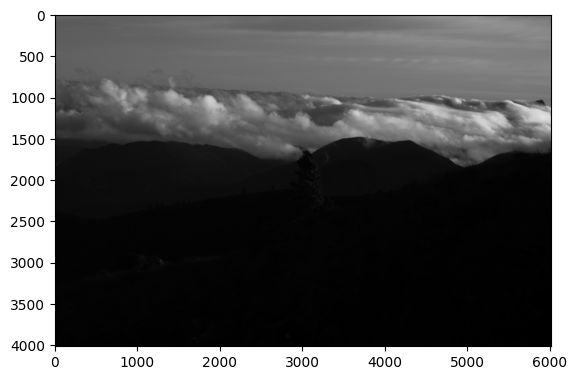

In [10]:
import rawpy
import matplotlib.pyplot as plt

with rawpy.imread(r'C:\soft\cv_vibrometry\Code\EUR_1584.NEF') as raw:
    bayer_pattern = raw.raw_image.copy()

plt.imshow(bayer_pattern, cmap='gray')
plt.show()

In [ ]:
pip install tensorflow

In [ ]:

with rawpy.imread(r'C:\soft\cv_vibrometry\Code\EUR_1584.NEF') as raw:
    bayer_pattern = raw.raw_image.copy()

In [ ]:
import tensorflow as tf

image = tf.io.decode_jpeg(image, channels=1)
image = tf.image.resize(image, size=[400, 400])

img = tf.squeeze(image).numpy()
plt.figure(figsize=(6, 6))
plt.imshow(img, cmap='gray')
plt.axis('off')
plt.show();
img

In [ ]:
# YOUR CODE HERE: Define a kernel with 3 rows and 3 columns.
kernel = tf.constant([
    [1,2,1],
    [2,4,2],
    [1,2,1],
])

# Reformat for batch compatibility.
image = tf.image.convert_image_dtype(image, dtype=tf.float32)
image = tf.expand_dims(image, axis=0)
kernel = tf.reshape(kernel, [*kernel.shape, 1, 1])
kernel = tf.cast(kernel, dtype=tf.float32)

conv_fn = tf.nn.conv2d

image_filter = conv_fn(
    input=image,
    filters=kernel,
    strides=1, # or (1, 1)
    padding='SAME',
)

plt.imshow(
    # Reformat for plotting
    tf.squeeze(image_filter)
)
plt.axis('off')
plt.show()

In [ ]:
relu_fn = tf.nn.relu

image_detect = relu_fn(image_filter)

plt.imshow(
    # Reformat for plotting
    tf.squeeze(image_detect)
)
plt.axis('off')
plt.show()

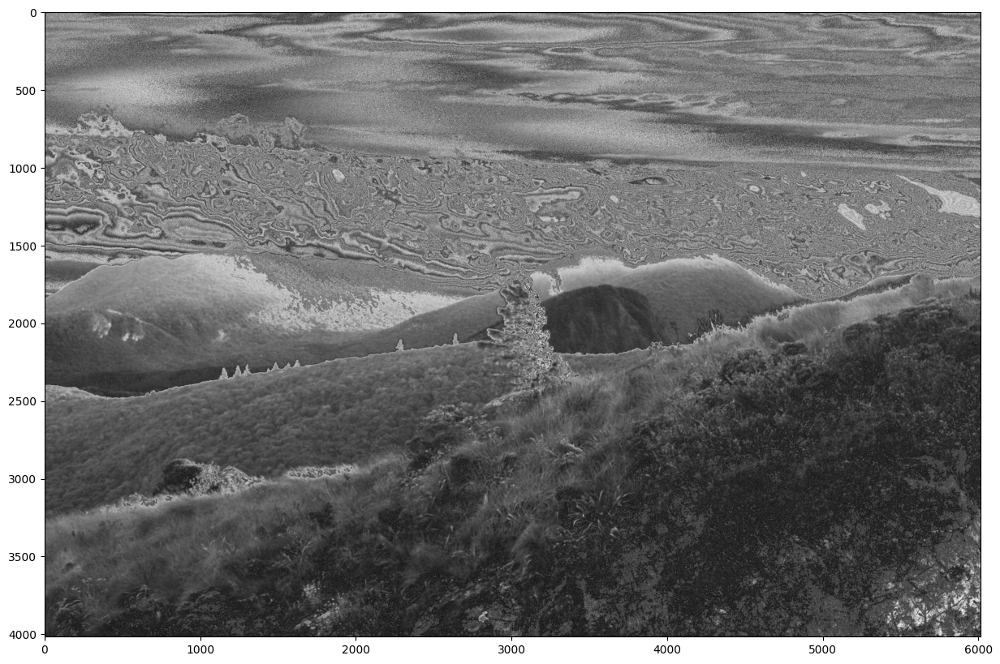

In [84]:
import rawpy
import matplotlib.pyplot as plt

with rawpy.imread(r'C:\soft\Personal\cv_vibrometry\Code\EUR_1584.NEF') as raw:
    bayer_pattern = raw.raw_image.copy()

plt.figure(figsize=(20, 10))
plt.imshow(bayer_pattern*100, cmap='gray')
# plt.axis('off')
plt.show()

In [74]:
import tensorflow as tf
import matplotlib.pyplot as plt

image = tf.convert_to_tensor(bayer_pattern)
image = tf.squeeze(image)

image = tf.image.convert_image_dtype(image, dtype=tf.float32)

light = 30
threshold = 0.02


In [75]:

dark_mask = tf.less(image, threshold)

dark_mask_float = tf.cast(dark_mask, dtype=tf.float32)

brightened_image = image * light
image = tf.where(dark_mask, brightened_image, image)
image = tf.expand_dims(image, axis=-1)   
image = tf.expand_dims(image, axis=0)    


Text(0.5, 1.0, 'Input')

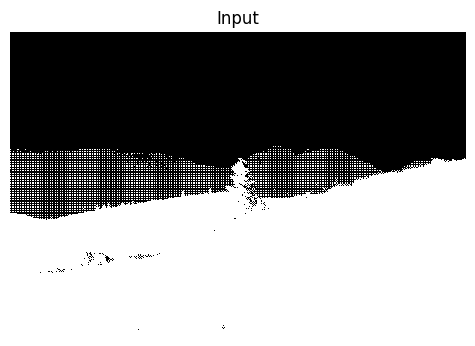

In [76]:
plt.figure(figsize=(20, 15))
plt.subplot(131)
plt.imshow(tf.squeeze(dark_mask), cmap='gray', interpolation='nearest')
plt.axis('off')
plt.title('Input')

In [77]:


kernel = tf.constant([
    [-1, -1, -1],
    [-1,  8, -1],
    [-1, -1, -1],
], dtype=tf.float32)

kernel = tf.reshape(kernel, [3, 3, 1, 1])

image_filter = tf.nn.conv2d(
    input=image,
    filters=kernel,
    strides=[1, 1, 1, 1],
    padding='SAME',
)

image_detect = tf.nn.relu(image_filter)



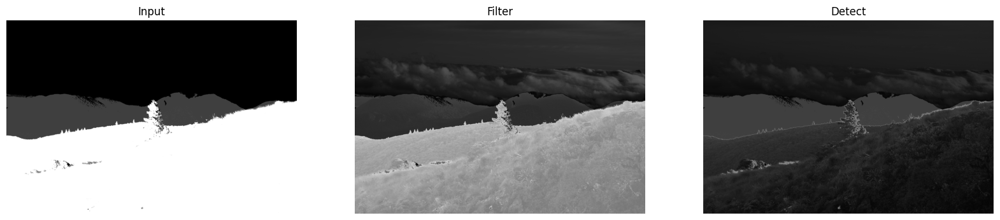

In [78]:
plt.figure(figsize=(20, 10))
plt.subplot(131)
plt.imshow(tf.squeeze(dark_mask), cmap='gray')
plt.axis('off')
plt.title('Input')
plt.subplot(132)
plt.imshow(tf.squeeze(image), cmap='gray')
plt.axis('off')
plt.title('Filter')
plt.subplot(133)
plt.imshow(tf.squeeze(image_detect),cmap='gray', vmin=0.0, vmax=1.0)
plt.axis('off')
plt.title('Detect')
plt.show()

In [ ]:
plt.figure(figsize=(20, 100))
plt.imshow(tf.squeeze(image_detect),cmap='gray', vmin=0.0, vmax=1.0)
plt.axis('off')
plt.title('Detect')
plt.show()

In [70]:
import cv2
import numpy as np

raw_numpy = image_detect.numpy()

raw_numpy = (raw_numpy * 255.0).astype(np.uint8)

imagem_rgb = cv2.cvtColor(raw_numpy, cv2.COLOR_BayerRG2RGB)


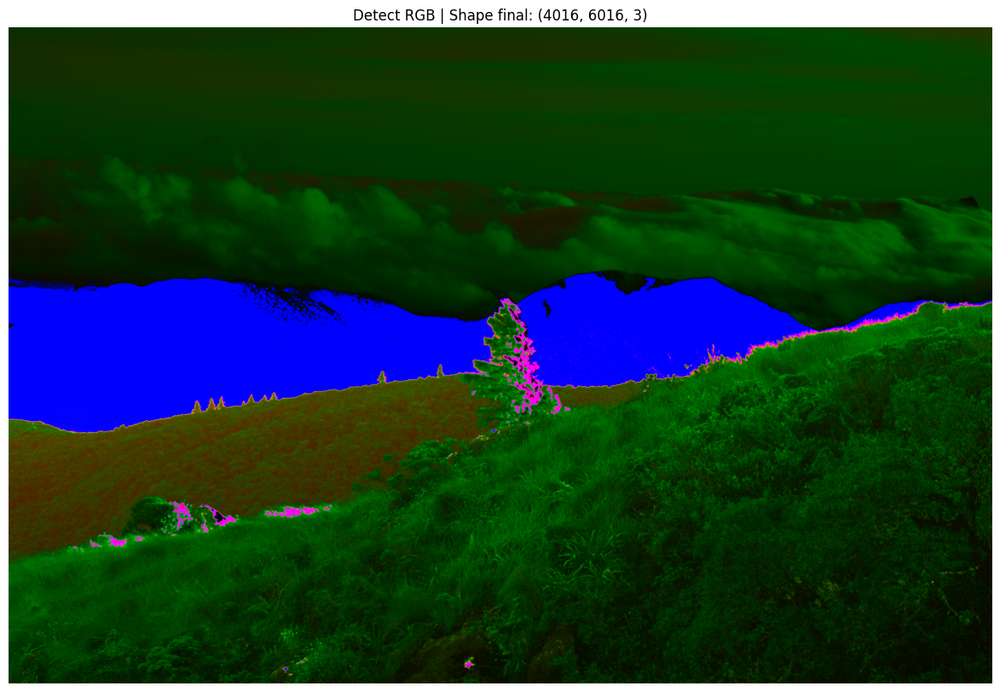

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


raw_numpy = np.squeeze(image_detect.numpy())


raw_numpy_clip = np.clip(raw_numpy, 0.0, 1.0)


raw_numpy_8bit = (raw_numpy_clip * 255.0).astype(np.uint8)


imagem_rgb = cv2.cvtColor(raw_numpy_8bit, cv2.COLOR_BayerRG2RGB)


plt.figure(figsize=(20, 10))
plt.imshow(imagem_rgb)
plt.axis('off')
plt.title(f'Detect RGB | Shape final: {imagem_rgb.shape}')
plt.show()